### why we need LangGraph : 

### Elements in LangGraph

#### 1.State :

#### 2.Node :
The node:

receives the current state

does some work

returns an update

#### 3.Edges : 

#### 4.Start :

#### 5.End : 

##### Tools :
 tools are like body parts for agent <br>
 here nodes can utilize tools to perform specific tasks such as fetching data from an API <br>
 Nodes are part of the graph structure while tools are functionalities used within nodes  <br>

 analogy : 

 tools in a ToolBox : A hammer for nails, a screwdriver for screws, each tool has a distinct purpose 


 ##### ToolNode :

 A ToolNode is just a special kind of node whose whose main job is to run a tool <br>

 it connects the tool's output back into the state, so other nodes can use that information

 ##### StateGrpah :

 A StateGraph is a class in LangGraph used to build and complie the graph structure

 #### Runnable :
 

#### Messages : 
##### 1. Human Message : Represents inputs from a user

##### 2. System Message : Used to Provide instructions or context to the model

##### 3. Function Message : Represents the result of a function call

##### 4. AI Message : Represents responses generated by AI models

##### 5. Tool Message : Similar to Function message, but specific to tool usage

### workflow - 1
This is basic workflow which has one node

In [3]:
from typing import Dict, TypedDict 
from langgraph.graph import StateGraph

# We now create an AgentState - shared data structure that keeps track of information as your application runs. 

class AgentState(TypedDict): # Our state schema
    message : str 


# we define nodes as functions where each nodes takes state as input and returns the modified state
def greeting_node(state: AgentState) -> AgentState:
    """Simple node that adds a greeting message to the state"""

    state['message'] = "Hey " + state["message"] + ", how is your day going?"

    return state 


#now we build graph using the StateGraph which  helps you design and manage the flow of tasks in your application using a graph structure
graph = StateGraph(AgentState)

graph.add_node("greeter", greeting_node)  #there are two ways to set entry point this is one way we show another say in next workflow

graph.set_entry_point("greeter")
graph.set_finish_point("greeter")

app = graph.compile()

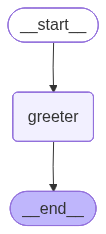

In [4]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [5]:
result = app.invoke({"message": "vishnu"})
result['message']

'Hey vishnu, how is your day going?'

### Workflow - 2 : conditional workflow 



In [6]:
from typing import TypedDict 
from langgraph.graph import StateGraph,START,END

class AgentState(TypedDict):
    number1: int 
    operation: str 
    number2: int
    finalNumber: int


##nodes 
def adder(state:AgentState) -> AgentState:
    """This node adds the 2 numbers"""
    state["finalNumber"] = state["number1"] + state["number2"]

    return state

def subtractor(state:AgentState) -> AgentState:
    """This node subtracts the 2 numbers"""
    state["finalNumber"] = state["number1"] - state["number2"]
    return state


def decide_next_node(state:AgentState) -> AgentState:
    """This node will select the next node of the graph"""

    if state["operation"] == "+":
        return "addition_operation"
    
    elif state["operation"] == "-":
        return "subtraction_operation" 


graph = StateGraph(AgentState)

graph.add_node("add_node", adder)
graph.add_node("subtract_node", subtractor)
graph.add_node("router", lambda state:state) # passthrough function

graph.add_edge(START, "router") 

graph.add_conditional_edges(
    "router",
    decide_next_node, 

    {
        # Edge: Node
        "addition_operation": "add_node",
        "subtraction_operation": "subtract_node"
    }

)

graph.add_edge("add_node", END)
graph.add_edge("subtract_node", END)

app = graph.compile()

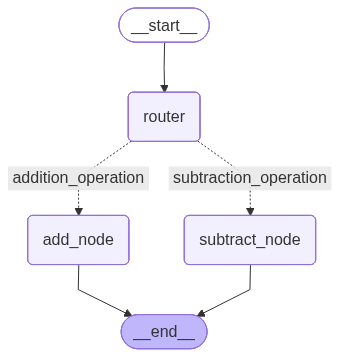

In [7]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [9]:
#### we can run it two ways 

#first way
initial_state_1 = AgentState(number1 = 10, operation="-", number2 = 5)
print(app.invoke(initial_state_1))


#second way 
result = app.invoke({"number1": 10, "operation": "-", "number2": 5})
print(result)

{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5}
{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5}


### Workflow - 3 : Looping workflow 


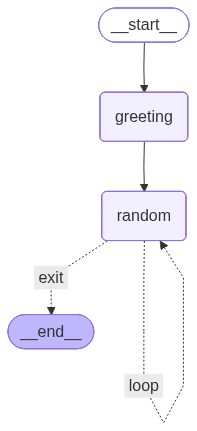

In [10]:
from langgraph.graph import StateGraph, END
import random
from typing import Dict, List, TypedDict

class AgentState(TypedDict):
    name: str
    number: List[int]
    counter: int
    
def greeting_node(state: AgentState) -> AgentState:
    """Greeting Node which says hi to the person"""
    state["name"] = f"Hi there, {state["name"]}"
    state["counter"] = 0 

    return state

def random_node(state: AgentState) -> AgentState:
    """Generates a random number from 0 to 10"""
    state["number"].append(random.randint(0, 10))
    state["counter"] += 1

    return state


def should_continue(state: AgentState) -> AgentState:
    """Function to decide what to do next"""
    if state["counter"] < 5:
        print("ENTERING LOOP", state["counter"])
        return "loop"  # Continue looping
    else:
        return "exit"  # Exit the loop

# greeting → random → random → random → random → random → END
graph = StateGraph(AgentState)

graph.add_node("greeting", greeting_node)
graph.add_node("random", random_node)
graph.add_edge("greeting", "random")


graph.add_conditional_edges(
    "random",     # Source node
    should_continue, # Action
    {
        "loop": "random",  
        "exit": END          
    }
)

graph.set_entry_point("greeting")

app = graph.compile()
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
# while working with parallel nodes we should not return the entire state,cause it will be overwritten by the other parallel nodes, so we should return only the modified state.
# state will be merged by the graph engine and passed to the next node.